# Analysis Report
**Name:** Addy Mager  
**Date:** November 15, 2026 

## Research question
Is the number of hashtags in an Instagram post related to its caption length, and does the average caption length differ between photo posts and reels?

## Hypotheses
- **Hypothesis 1:** Posts with more hashtags will tend to have longer captions.
- **Hypothesis 2:** Average caption length will differ between photo posts and reels.

## Dataset and source
This project uses the `liked_posts.json` file exported from my Instagram account. Each record includes a timestamp, post URL, caption, and hashtag data. The analysis uses caption word count and hashtag count as quantitative variables, and post type, such as photo posts or reels, as a categorical variable.

This dataset represents posts I liked, not all Instagram posts. It does not provide a measure of each post's engagement performance or popularity, so the analysis cannot determine which post type receives more likes. 

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

file_path = Path("liked_posts.json")

with file_path.open("r", encoding="utf-8") as file:
    raw_data = json.load(file)

print(f"Loaded {len(raw_data):,} records from {file_path}")

Loaded 19,327 records from liked_posts.json


## 1. Data preparation and exploration

The code that is below loads in the JSON file that extracts the information that is needed for this report and organizes them into a pandas DataFrame. Each of the rows will represent one of the posts. URLs that contain `/p/` are classified as Photo Posts, and URLs that contain `/reel/` are classified as Reels. Other records are excluded from the comparison.

The Caption word count is calculated by splitting the caption into many words, while the hashtag count is taken from the exported hashtag list. The empty captions are retained and counted as zero words, rather than being removed. 

In [2]:
records = []

for item in raw_data:
    url = ""
    caption = ""
    hashtag_count = 0

    for field in item.get("label_values", []):
        label = field.get("label", "")
        title = field.get("title", "")

        if label == "URL":
            url = field.get("value", "") or ""
        elif label == "Caption":
            caption = field.get("value", "") or ""
        elif title == "Hashtags":
            hashtag_items = field.get("dict", [])
            hashtag_count = len(hashtag_items) if isinstance(hashtag_items, list) else 0

    if "/reel/" in url.lower():
        post_type = "Reel"
    elif "/p/" in url.lower():
        post_type = "Photo Post"
    else:
        post_type = "Other"

    records.append({
        "Timestamp": item.get("timestamp"),
        "Post_Type": post_type,
        "Caption": caption,
        "Caption_Word_Count": len(caption.split()),
        "Caption_Char_Count": len(caption),
        "Hashtag_Count": hashtag_count
    })

df_raw = pd.DataFrame(records)

df = df_raw[df_raw["Post_Type"].isin(["Photo Post", "Reel"])].copy()

df["Date"] = pd.to_datetime(df["Timestamp"], unit="s", errors="coerce")

print(f"Total records loaded: {len(df_raw):,}")
print(f"Photo Posts and Reels retained: {len(df):,}")
print(f"Other records excluded: {(df_raw['Post_Type'] == 'Other').sum():,}")

display(df.head())

Total records loaded: 19,327
Photo Posts and Reels retained: 19,326
Other records excluded: 1


,Timestamp,Post_Type,Caption,Caption_Word_Count,Caption_Char_Count,Hashtag_Count,Date
0,1788348855,Reel,Skincare routine pt 2 ðð\n\n@dermalogica...,14,173,5,2026-09-02 11:34:15
1,1788347338,Photo Post,September plans in Northeast Ohio are official...,119,749,6,2026-09-02 11:08:58
2,1788317405,Reel,Skincare routine pt 1. I cannot emphasize enou...,44,315,4,2026-09-02 02:50:05
3,1788314918,Photo Post,Smiles from summer!! ð,4,25,0,2026-09-02 02:08:38
4,1788312957,Reel,i donât wanna know,4,20,0,2026-09-02 01:35:57


In [3]:
# Inspect data types, missing values, category counts, and summary statistics
print("DataFrame information:")
df.info()

print("\nPost type counts:")
print(df["Post_Type"].value_counts(dropna=False))

cols = ["Caption_Word_Count", "Caption_Char_Count", "Hashtag_Count"]

print("\nMissing values:")
print(df[cols].isna().sum())

print("\nSummary statistics:")
print(df[cols].describe().round(2))

print("\nSummary statistics by post type:")
print(
    df.groupby("Post_Type", dropna=False)[cols]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

DataFrame information:
<class 'pandas.DataFrame'>
Index: 19326 entries, 0 to 19326
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype        
---  ------              --------------  -----        
 0   Timestamp           19326 non-null  int64        
 1   Post_Type           19326 non-null  str          
 2   Caption             19326 non-null  str          
 3   Caption_Word_Count  19326 non-null  int64        
 4   Caption_Char_Count  19326 non-null  int64        
 5   Hashtag_Count       19326 non-null  int64        
 6   Date                19326 non-null  datetime64[s]
dtypes: datetime64[s](1), int64(4), str(2)
memory usage: 4.4 MB

Post type counts:
Post_Type
Reel          9820
Photo Post    9506
Name: count, dtype: int64

Missing values:
Caption_Word_Count    0
Caption_Char_Count    0
Hashtag_Count         0
dtype: int64

Summary statistics:
       Caption_Word_Count  Caption_Char_Count  Hashtag_Count
count            19326.00            19326.00    

## 2. Basic visualizations
These initial visualizations show the distribution of caption lengths, the relationship between hashtag count and caption length, and the differences in caption length between photo posts and reels.

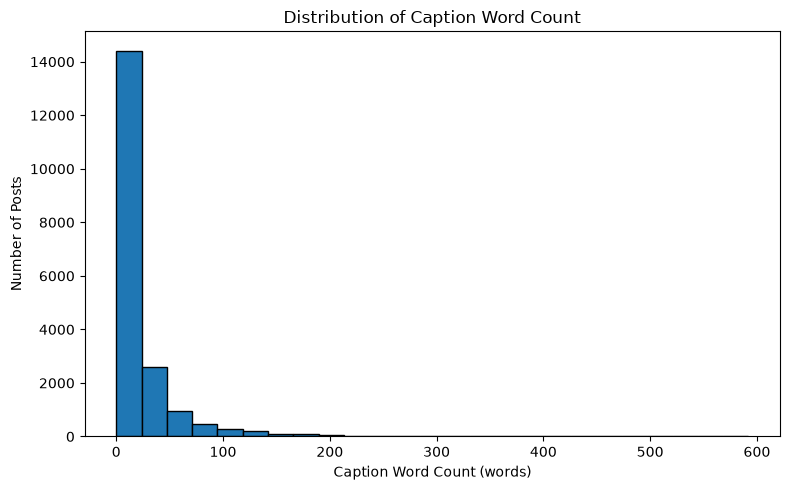

In [4]:
# Basic histogram: distribution of caption word counts
plt.figure(figsize=(8, 5))
plt.hist(df["Caption_Word_Count"], bins=25, edgecolor="black")
plt.title("Distribution of Caption Word Count")
plt.xlabel("Caption Word Count (words)")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()

### Histogram interpretation

The histogram uses 25 bins in the initial visualization to group the caption lengths into intervals. Using more bins will provide a greater detail about the distribution, while fewer bins will create a simpler overview. The number of bins can affect how clearly patterns, clusters, and unusually long captions appear. 

This distribution is strongly right-skewed, meaning that the most posts have shorter captions while a smaller number have very long captions. These unusually long captions will create a tail that extends toward the right side of the histogram. 

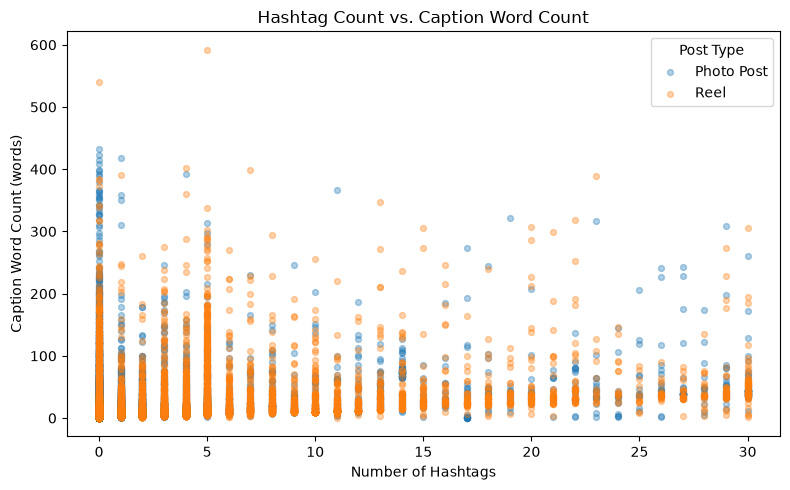

In [5]:
# Basic scatter plot: hashtag count compared with caption word count
plt.figure(figsize=(8, 5))

for post_type in ["Photo Post", "Reel"]:
    subset = df[df["Post_Type"] == post_type]
    plt.scatter(
        subset["Hashtag_Count"],
        subset["Caption_Word_Count"],
        label=post_type,
        alpha=0.35,
        s=18
    )

plt.title("Hashtag Count vs. Caption Word Count")
plt.xlabel("Number of Hashtags")
plt.ylabel("Caption Word Count (words)")
plt.legend(title="Post Type")
plt.tight_layout()
plt.show()

### Scatter plot interpretation

The scatter plot compares hashtag count with caption word count. The points show a slight upward tendency, suggesting that posts with more hashtags may also have somewhat longer captions. However, the points are widely spread, so hashtag count alone does not explain caption length very well. The two post types overlap considerably.

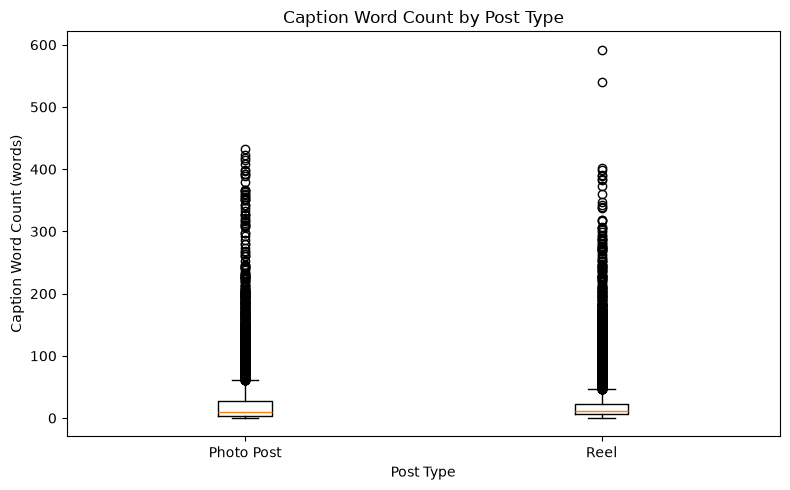

In [6]:
# Basic boxplot: compare caption word counts by post type
photo_words = df.loc[df["Post_Type"] == "Photo Post", "Caption_Word_Count"]
reel_words = df.loc[df["Post_Type"] == "Reel", "Caption_Word_Count"]

plt.figure(figsize=(8, 5))
plt.boxplot([photo_words, reel_words])
plt.xticks([1, 2], ["Photo Post", "Reel"])

plt.title("Caption Word Count by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Caption Word Count (words)")

plt.tight_layout()
plt.show()

### Boxplot interpretation

The boxplot compares the distribution of the caption word counts for both photo posts and reels. The photo posts have a slightly higher average in the caption length, while the reels have a higher median length. This suggests that the typical caption length is slightly higher for the reels, even though some longer photo post captions have increased their overall average. Both groups show similar median and spread of caption word counts for photo posts and reels. The two distributions are similar, although photo posts have a slightly higher average caption length. Both groups contain long-caption outliers, which contribute to the right-skewed distributions.

## 3. Styled visualizations and design choices

The final versions use a consistent visual style to make the charts feel and look like one set. I used blue and orange to make the distinctions for the photo posts and reels, clear titles and axis labels, larger figure sizes, and subtle gridlines. For the histogram it includes the mean and median reference lines. The scatter plot uses transparency and different marker shapes to make overlapping points to distinguish everything easier. Finally, the boxplot uses matching group colors to display each group's sample size.

The styled histogram limits the visible x-axis to 100 words so the main distribution is easier to read. Captions longer than 100 words are still included in the dataset and statistical analysis; they are only outside the displayed range of that chart.

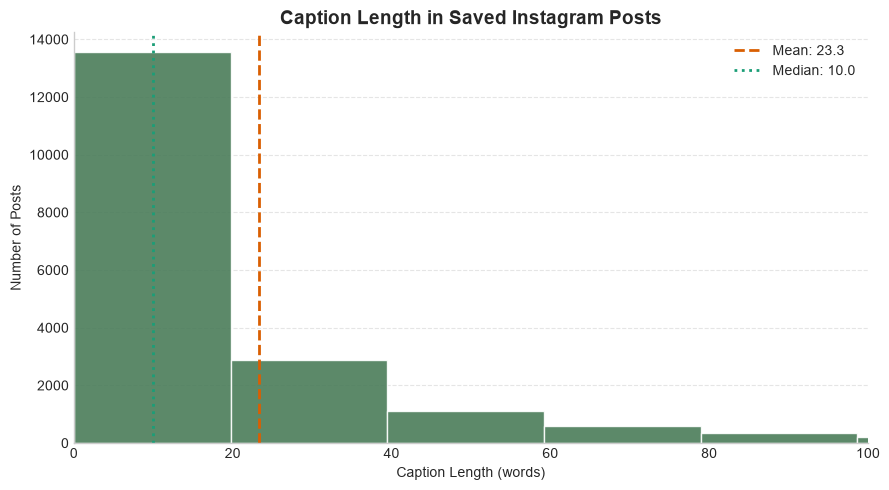

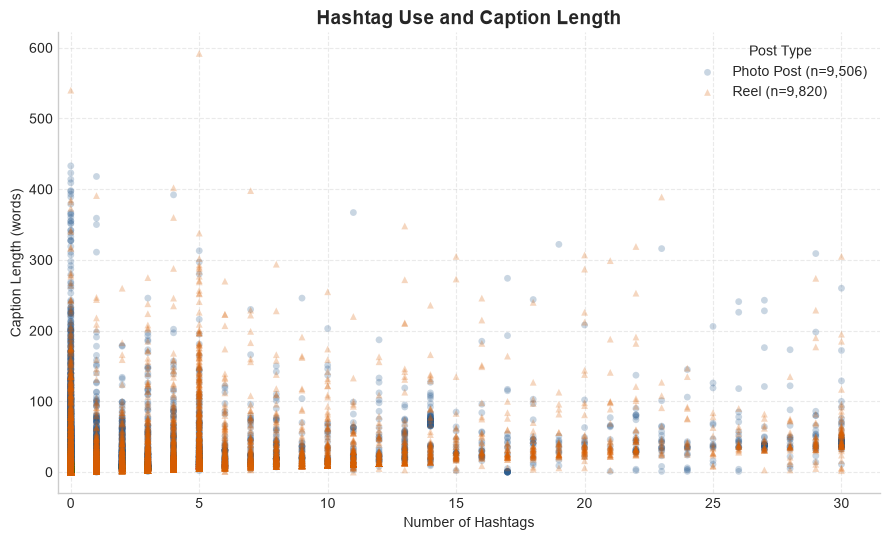

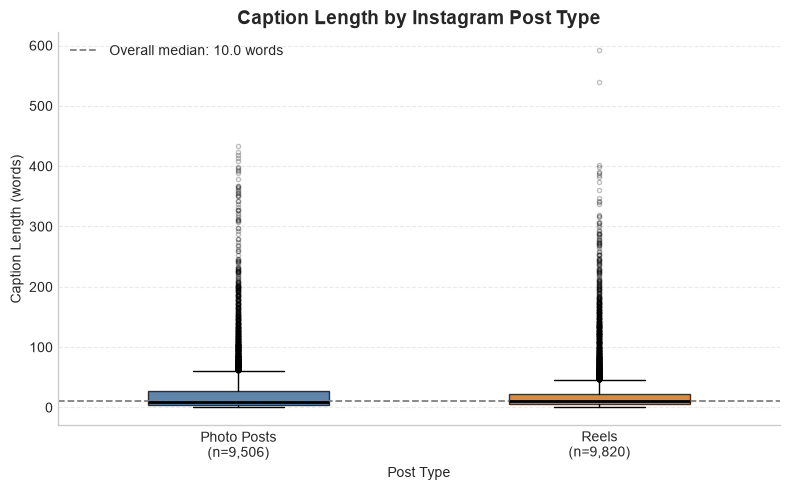

In [7]:
# Consistent style and colors for the final figures
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

colors = {"Photo Post": "#2B5C8F", "Reel": "#D95F02"}

# Styled Figure 1: histogram
fig, ax = plt.subplots(figsize=(9, 5))

mean_words = df["Caption_Word_Count"].mean()
median_words = df["Caption_Word_Count"].median()

ax.hist(
    df["Caption_Word_Count"],
    bins=30,
    color="#4A7C59",
    edgecolor="white",
    alpha=0.9
)
ax.axvline(mean_words, color="#D95F02", linestyle="--", linewidth=2,
           label=f"Mean: {mean_words:.1f}")
ax.axvline(median_words, color="#1B9E77", linestyle=":", linewidth=2,
           label=f"Median: {median_words:.1f}")

ax.set_title("Caption Length in Saved Instagram Posts", fontsize=14, fontweight="bold")
ax.set_xlabel("Caption Length (words)")
ax.set_ylabel("Number of Posts")
ax.set_xlim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

# Styled Figure 2: scatter plot
fig, ax = plt.subplots(figsize=(9, 5.5))

markers = {"Photo Post": "o", "Reel": "^"}
for post_type in ["Photo Post", "Reel"]:
    subset = df[df["Post_Type"] == post_type]
    ax.scatter(
        subset["Hashtag_Count"],
        subset["Caption_Word_Count"],
        label=f"{post_type} (n={len(subset):,})",
        color=colors[post_type],
        marker=markers[post_type],
        alpha=0.25,
        s=24,
        edgecolors="none"
    )

ax.set_title("Hashtag Use and Caption Length", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of Hashtags")
ax.set_ylabel("Caption Length (words)")
ax.set_xlim(left=-0.5)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(title="Post Type")
plt.tight_layout()
plt.show()

# Styled Figure 3: boxplot
fig, ax = plt.subplots(figsize=(8, 5))

box = ax.boxplot(
    [photo_words, reel_words],
    patch_artist=True,
    widths=0.5,
    medianprops={"color": "black", "linewidth": 2},
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.25}
)

# Set x-axis labels separately for compatibility with newer Matplotlib versions
ax.set_xticks([1, 2])
ax.set_xticklabels([
    f"Photo Posts\n(n={len(photo_words):,})",
    f"Reels\n(n={len(reel_words):,})"
])

for patch, post_type in zip(box["boxes"], ["Photo Post", "Reel"]):
    patch.set_facecolor(colors[post_type])
    patch.set_alpha(0.75)

ax.axhline(
    median_words,
    color="gray",
    linestyle="--",
    linewidth=1.3,
    label=f"Overall median: {median_words:.1f} words"
)
ax.set_title("Caption Length by Instagram Post Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Post Type")
ax.set_ylabel("Caption Length (words)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Statistical Analysis Interpretation 

Two OLS regression models are used. The first compares caption word count between photo posts and reels. The second examines the relationship between hashtag count and caption word count. The regression output includes estimated coefficients, p-values, and R-squared values.

A small p-value indicates evidence of an association in this dataset, but it does not automatically mean the association is large or practically important. Neither model can establish that one variable causes another.

In [8]:
# Model 1: compare caption length between Photo Posts and Reels
model_groups = smf.ols("Caption_Word_Count ~ C(Post_Type)", data=df).fit()

print("OLS model: Caption word count by post type")
print(model_groups.summary())

print("\nCaption word count by post type:")
display(
    df.groupby("Post_Type")["Caption_Word_Count"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

# Model 2: relationship between hashtag count and caption word count
model_relationship = smf.ols("Caption_Word_Count ~ Hashtag_Count", data=df).fit()

print("\nOLS model: Caption word count predicted by hashtag count")
print(model_relationship.summary())

correlation = df["Hashtag_Count"].corr(df["Caption_Word_Count"])
print(f"\nPearson correlation (r): {correlation:.3f}")

OLS model: Caption word count by post type
                            OLS Regression Results                            
Dep. Variable:     Caption_Word_Count   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     9.730
Date:                Sat, 14 Nov 2026   Prob (F-statistic):            0.00182
Time:                        20:33:47   Log-Likelihood:                -98008.
No. Observations:               19326   AIC:                         1.960e+05
Df Residuals:                   19324   BIC:                         1.960e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

,count,mean,median,std
Post_Type,,,,
Photo Post,9506,24.15,9.0,39.97
Reel,9820,22.41,11.0,37.16



OLS model: Caption word count predicted by hashtag count
                            OLS Regression Results                            
Dep. Variable:     Caption_Word_Count   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     668.0
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          7.96e-145
Time:                        20:33:47   Log-Likelihood:                -97685.
No. Observations:               19326   AIC:                         1.954e+05
Df Residuals:                   19324   BIC:                         1.954e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

## 5. Conclusion and reflection
In this report, photo posts have an average caption length of approximately 24.15 words, compared with 22.41 words for the reels. The estimated difference is statistically significant, but it is relatively small. Reels have an average of about 1.73 words, which is fewer than the photo posts. The very low R-squared value indicates that post type explains almost none of the variation in caption length.

In this report, photo posts have an average caption length of approximately 24.15 words, compared with 22.41 words for Reels. The estimated difference is statistically significant, but relatively small. Reels have an average of approximately 1.73 fewer words than Photo Posts. The very low R-squared value indicates that post type explains almost none of the variation in caption length.

The hashtag count has a very weak and positive relationship with the caption length. The model estimates that each of the additional hashtag is associated with about 1.29 additional caption words, and the correlation is approximately 0.183. The R-squared value is about 0.033, meaning the hashtag count explains only a small portion of the variation in caption length. These results provide limited support for the first hypothesis, but they do not show that adding hashtags causes captions to become longer.

The boxplot was the most effective visualization because it made it easier to compare the median caption lengths, spreads, and the outliers between the photo posts and reels. For the statistical analysis, it also revealed that some relationships were statistically significant even though their practical effects were relatively small.

There are several limitations in this dataset. The dataset contains posts I liked, not a random sample of all Instagram posts. The findings cannot be generalized to all Instagram users or posts. The export does not include post performance measures, so this analysis cannot determine whether hashtags or caption length lead to more likes or engagement. The caption length is strongly right-skewed, with a small number of very long captions. Extreme values can affect OLS regression results, and other factors not included in the dataset may influence caption length.

Some additional information, such as likes, comments, shares, and posting dates, could improve this investigation by providing a better understanding of how caption length, hashtags, and post types could relate to the audience engagement. 

### Reflection 
Overall, this analysis report allowed me to practice with loading and cleaning nested JSON data, creating variables with pandas, exploring data with visualizations (charts, histograms, box plots, etc.), and interpreting regression results. This analysis report also demonstrated why statistical significance and practical importance should be considered separately. 

# AI Disclosure 


**AI Tool:** ChatGPT

**Prompts Used:**
- "code"

For my likes report, I used ChatGPT to help me with my code when it came to errors and some troubleshooting. I also used ChatGPT to help me understand my code, but it helped me to fix my problems with my API Python code while working with my Instagram data. I also took the time to review the suggested code and use parts of it to help me complete my report that I created. 

Finally, the interpretations and conclusions in this report are my own understanding of my Instagram data.